In [14]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.stats import linregress
from tqdm.auto import tqdm
from dask.diagnostics import ProgressBar
import cartopy.feature as cfeature
import xesmf
import dask
import glob
import os
import seaborn as sns
import pandas as pd
import geopandas as gpd
from dask_jobqueue import PBSCluster
from dask.distributed import Client
import matplotlib as mpl
import matplotlib.gridspec as gridspec
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
# Setup your PBSCluster
cluster = PBSCluster(
    cores=20,  # Total number of cores across all processes
    memory='300GB',  # Memory per worker
    processes=20,  # Number of processes per worker (1 process per core)
    queue='casper',  # The type of queue to utilize
    local_directory='/glade/derecho/scratch/adixit/tmp/',  # Use your local directory
    resource_spec='select=1:ncpus=10:mem=300GB',  # Resources per worker
    account='UCOR0105',  # Project ID
    walltime='1:00:00',  # Wall time
    #interface='ib0',  # Interface to use (if needed)
)

cluster.scale(jobs=1)  # This will create 200 workers
client = Client(cluster)

In [3]:
client

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: /node/crhtc92.hpc.ucar.edu/50284/proxy/8787/status,
Dashboard: /node/crhtc92.hpc.ucar.edu/50284/proxy/8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.200:35847,Workers: 0
Dashboard: /node/crhtc92.hpc.ucar.edu/50284/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


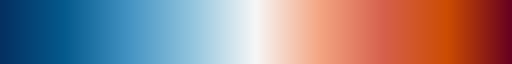

In [10]:
from matplotlib.colors import LinearSegmentedColormap
combined_colors = ['#67001f','#cc4c02','#d6604d','#f4a582','#f7f7f7','#92c5de','#4393c3','#045a8d','#053061']
def create_gradient_colormap(n_colors, color_list=combined_colors):
    return LinearSegmentedColormap.from_list("custom_gradient", color_list, N=n_colors)
cmap1 = create_gradient_colormap(256,combined_colors[::-1])
cmap1

In [41]:
start_date = '1930-01-01'
end_date = '2100-12-31'
months = [4,5,6,7]

@dask.delayed
def d00_trend(le,var):
    ds = xr.open_mfdataset('/glade/campaign/cgd/cesm/CESM2-LE/atm/proc/tseries/day_1/%s/*%s*.nc' %(var,le))['%s' %(var)]
    ds['lon'] = ds['lon']
    ds = ds.rename({'lon':'longitude','lat':'latitude'})
    data = ds.sel(time=slice(start_date,end_date))
    return data

files = sorted(glob.glob('/glade/campaign/cgd/cesm/CESM2-LE/atm/proc/tseries/day_1/TREFHTMX/*.nc'))
files = [os.path.basename(x) for x in files]
unique_members = sorted(set(".".join(f.split(".")[4:6]) for f in files))

ds_d00 = {}
for le in unique_members:
    fsr = d00_trend(le,'TREFHTMX')
    ds_d00[le] = fsr

In [43]:
ds_d00 = dask.compute(ds_d00)[0]

In [45]:
ds = xr.concat(ds_d00.values(),dim='lemem')

In [47]:
ds_fr = ds.mean(dim='lemem')

In [50]:
ds_fr_6 = ds_fr.sel(time=ds_fr.time.dt.month.isin([6])).resample(time='YS').mean()

In [61]:
ds_fr_6 = dask.compute(ds_fr_6)[0]

/glade/work/adixit/conda-envs/dask/lib/python3.10/site-packages/distributed/client.py:3164: UserWarning: Sending large graph of size 170.89 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


In [62]:
ds_fr_6.to_netcdf('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/TREFHTMX.forced-response.June.1930-2100.nc')

In [36]:
ds = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/TREFHTMX.forced-response.May.1930-2100.nc')

In [37]:
ds = ds['TREFHTMX']

In [38]:
def calc_trend(ds):
    from scipy.stats import t
    factor = 365.2425 * 24 * 3600 * 1e9 * 10
    ds = ds.rolling(time=10, center=True).mean()
    fit = ds.polyfit('time', 1, cov=True)
    slope = fit.polyfit_coefficients.sel(degree=1)
    se = np.sqrt(fit.polyfit_covariance.sel(cov_i=0, cov_j=0))
    pval = xr.apply_ufunc(lambda x: 2*t.sf(np.abs(x), ds.sizes['time']-2), slope/se)
    return slope * factor, pval

def plot_simulated(llon, llat, prec, row, col, levs, cmap1, shape_feature, ax1, ds_sig=None):
    g = ax1.gridlines(draw_labels=False)
    g.bottom_labels = row == 0
    g.left_labels = col == 0
    g.top_labels = g.right_labels = False
    g.xlines = g.ylines = False
    g.xlabel_style = g.ylabel_style = {'size': 7.5, 'color': 'k'}
    pc1 = ax1.contourf(llon, llat, prec, cmap=cmap1,transform=ccrs.PlateCarree(), levels=levs, extend='both')
    ax1.add_geometries(shape_feature.geometry, crs=ccrs.PlateCarree(),
                       facecolor='none', edgecolor='#525252', linewidth=0.75)

    if ds_sig is not None:
        plt.rcParams['hatch.linewidth'] = 0.25
        cs = ax1.contourf(ds_sig.longitude, ds_sig.latitude, ds_sig.astype(int),
                 levels=[0.5, 1.5], colors='none', hatches=['...'],
                 transform=ccrs.PlateCarree())
        for c in cs.collections:
            c.set_edgecolor('#525252')  # Hatch color
            c.set_linewidth(0)      # Hatch line thickness
    return pc1

/glade/derecho/scratch/adixit/tmp/ipykernel_130708/2719459124.py:27: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed two minor releases later.
  for c in cs.collections:
/glade/derecho/scratch/adixit/tmp/ipykernel_130708/2719459124.py:27: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed two minor releases later.
  for c in cs.collections:


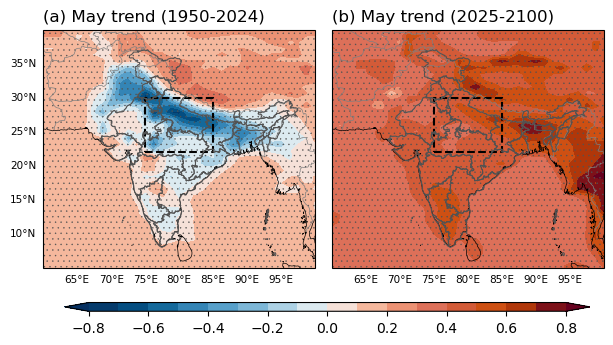

In [39]:
import matplotlib.patches as patches

shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
gdf = gpd.read_file(shp_file)

f = plt.figure(figsize=(7, 3.5))
gs1 = gridspec.GridSpec(1, 2)
gs1.update(left=0.099, bottom=0.20, wspace=0.06, hspace=0.16)

levs = np.arange(-0.8,0.81,0.1)
c1diff = cmap1


years_plot = [slice('1950','2024'),slice('2025','2100')]
title_list = ['(a) May trend (1950-2024)','(b) May trend (2025-2100)']

for i in np.arange(2):
    ax1 = f.add_subplot(gs1[0, i], projection=ccrs.PlateCarree())
    ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
    ax1.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='gray')
    data, pval = calc_trend(ds.sel(time=years_plot[i]))
    da_sig = pval<0.05
    pc = plot_simulated(data.longitude, data.latitude, data, 0, i,levs, c1diff, gdf, ax1, ds_sig=da_sig)
    
    
    ax1.set_extent([60, 100, 5, 40], crs=ccrs.PlateCarree())
    #ax1.set_xticks(np.arange(60, 111, 10), crs=ccrs.PlateCarree())
    #ax1.set_yticks(np.arange(10, 46, 10), crs=ccrs.PlateCarree())
    ax1.tick_params(labelsize=8)
    
    rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k',
                                   facecolor='none', linewidth=1.5, linestyle='--')
    ax1.add_patch(rectangle2)
    ax1.set_title(title_list[i],loc='left')
    #plt.savefig("May-TREFHTMX_verify.pdf",dpi=300,format='pdf',transparent=True)
cbar_ax = f.add_axes([0.13, 0.075, 0.75, 0.025])
cb = plt.colorbar(pc, cax=cbar_ax, orientation='horizontal', extend='both')
#cb.ax.set_title('Intensity', fontsize=9)
plt.savefig("May-TREFHTMX_verify.pdf",dpi=300,format='pdf',transparent=True)
plt.show()

In [40]:
ds = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/TREFHTMX.forced-response.June.1930-2100.nc')

In [41]:
ds = ds['TREFHTMX']

/glade/derecho/scratch/adixit/tmp/ipykernel_130708/2719459124.py:27: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed two minor releases later.
  for c in cs.collections:
/glade/derecho/scratch/adixit/tmp/ipykernel_130708/2719459124.py:27: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed two minor releases later.
  for c in cs.collections:


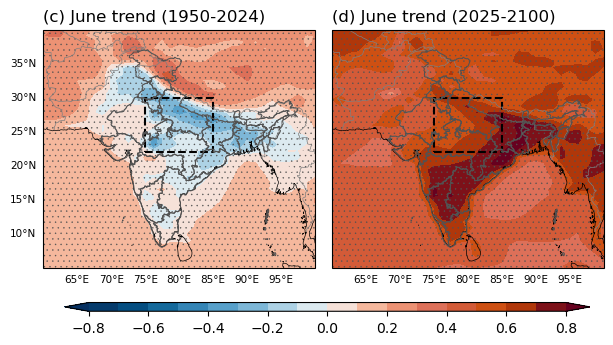

In [42]:
import matplotlib.patches as patches

shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
gdf = gpd.read_file(shp_file)

f = plt.figure(figsize=(7, 3.5))
gs1 = gridspec.GridSpec(1, 2)
gs1.update(left=0.099, bottom=0.20, wspace=0.06, hspace=0.16)

levs = np.arange(-0.8,0.81,0.1)
c1diff = cmap1
factor = 365.2425 * 24 * 3600 * 1e9 * 10

years_plot = [slice('1950','2024'),slice('2025','2100')]
title_list = ['(c) June trend (1950-2024)','(d) June trend (2025-2100)']

for i in np.arange(2):
    ax1 = f.add_subplot(gs1[0, i], projection=ccrs.PlateCarree())
    ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
    ax1.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='gray')
    data, pval = calc_trend(ds.sel(time=years_plot[i]))
    da_sig = pval<0.05
    pc = plot_simulated(data.longitude, data.latitude, data, 0, i,levs, c1diff, gdf, ax1, ds_sig=da_sig)
    
    
    ax1.set_extent([60, 100, 5, 40], crs=ccrs.PlateCarree())
    #ax1.set_xticks(np.arange(60, 111, 10), crs=ccrs.PlateCarree())
    #ax1.set_yticks(np.arange(10, 46, 10), crs=ccrs.PlateCarree())
    ax1.tick_params(labelsize=8)
    
    rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k',
                                   facecolor='none', linewidth=1.5, linestyle='--')
    ax1.add_patch(rectangle2)
    ax1.set_title(title_list[i],loc='left')
    #plt.savefig("May-TREFHTMX_verify.pdf",dpi=300,format='pdf',transparent=True)
cbar_ax = f.add_axes([0.13, 0.075, 0.75, 0.025])
cb = plt.colorbar(pc, cax=cbar_ax, orientation='horizontal', extend='both')
#cb.ax.set_title('Intensity', fontsize=9)
plt.savefig("June-TREFHTMX_verify.pdf",dpi=300,format='pdf',transparent=True)
plt.show()

In [5]:
ds = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/TREFHTMX.forced-response.May.1930-2100.nc')
df_may = ds['TREFHTMX'].sel(latitude=slice(22,30),longitude=slice(75,85)).mean(dim=['latitude','longitude'])

ds = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/TREFHTMX.forced-response.June.1930-2100.nc')
df_june = ds['TREFHTMX'].sel(latitude=slice(22,30),longitude=slice(75,85)).mean(dim=['latitude','longitude'])

In [6]:
df_may = df_may.assign_coords(time=df_may.time.dt.year,dtype='datetime64')-273.15
df_june = df_june.assign_coords(time=df_june.time.dt.year,dtype='datetime64')-273.15

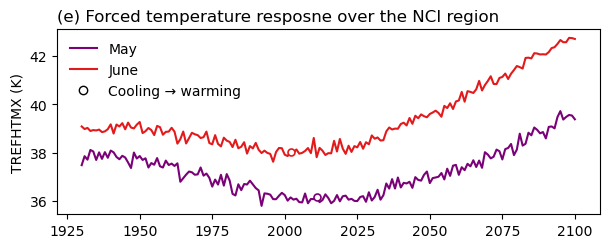

In [56]:
plt.rcdefaults()
fig, ax = plt.subplots(figsize=(7, 2.4))

for da, name, c in [(df_may, 'May', '#7a0177'), (df_june, 'June', '#e31a1c')]:
    i = int(da.rolling(time=20, center=True).mean().argmin('time'))     # turning point of the 7-day smoothed series
    da.plot(ax=ax, color=c,  label=f"{name}")
    ax.plot(da.time[i], da[i], 'o', ms=5, mfc='white', mec=c, mew=1.2, zorder=3)

ax.plot([], [], 'o', mfc='white', mec='k', label='Cooling → warming')
ax.set(xlabel='', ylabel='TREFHTMX (K)', title='')
#ax.set_xlim([1950,2100])
ax.legend(frameon=False, loc='upper left')
ax.set_title('(e) Forced temperature resposne over the NCI region' ,loc='left')
#plt.savefig("TREFHTMX_verify_warming.pdf",dpi=300,format='pdf',transparent=True)
plt.show()